# Modelado

**Configuración del entorno.** Se importan librerías y funciones auxiliares.

In [1]:
import os

RANDOM_SEED = 8
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
import sys
sys.path.append('..')  # carpeta src/

from utils.sequences import to_dataset
from utils.preprocessing import to_log_retornos

**Constantes.** Se definen los parámetros constantes que se usarán.

In [3]:
# Modelado
WINDOW_SIZE = 4                 # semanas de contexto
TEST_SIZE, VAL_SIZE= 0.2, 0.2   # fracción reservada a test y validación
TARGET = 'M_281/320KG_E'        # categoría a predecir

# Entrenamiento
EPOCHS = 10_000
PATIENCE = 20
BATCH_SIZE = 16
LEARNING_RATE = 1e-4

# Ajuste fino semanal
N_RECENT = 52                   # semanas en el re-entrenamiento
FT_EPOCHS = 10                  # épocas de ajuste fino
FT_LR = LEARNING_RATE / 10      # learning rate del ajuste fino

**Reproducibilidad.** Se fijan las semillas y se fuerzan operaciones deterministas, de modo que dos entrenamientos con los mismos datos produzcan el mismo modelo.

In [4]:
def set_seed(seed: int = RANDOM_SEED):
    """Resultados reproducibles."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.config.experimental.enable_op_determinism()

**Carga de los datos.** Se carga el conjunto de datos, con una fila por semana y una columna por categoría *sex_weight_type* (creado en `preprocessing.ipynb`).

In [5]:
PATH_CLEAN_DATA = '../../data/BinefarBovinePriceCleaned.csv'

df_data = pd.read_csv(PATH_CLEAN_DATA, sep=';', index_col='date', parse_dates=True)
target_idx = df_data.columns.get_loc(TARGET)

n_rows, n_cols = df_data.shape
print(f'Dimensiones:\n- núm. registros: {n_rows}\n- núm. variables: {n_cols}')

Dimensiones:
- núm. registros: 619
- núm. variables: 32


**Construcción dataset.** Se construyen dos versiones con las mismas muestras:

* **Precios** (€/kg).
* **Log-retornos** semanales: $100\,\ln(p_t / p_{t-1})$.

Cada muestra de entrada contiene `WINDOW_SIZE` registros consecutivos y su salida es el valor de la categoría estudiada la semana siguiente.

In [6]:
prices = df_data.to_numpy()
log_returns = 100 * to_log_retornos(prices) # una fila menos que prices

x, y = to_dataset(
    prices[1:],
    WINDOW_SIZE,
    target=target_idx
)

x_log, y_log = to_dataset(
    log_returns,
    WINDOW_SIZE,
    target=target_idx
)

dates = df_data.index[WINDOW_SIZE + 1 :]  # fecha objetivo de cada muestra
last_price = x[:, -1, [target_idx]]       # precio del objetivo la semana anterior

print(f'x: {x.shape}, x_log: {x_log.shape} (muestras, semanas, variables)')
print(f'y: {y.shape}, y_log: {y_log.shape} (muestras, variables objetivo)')

x: (614, 4, 32), x_log: (614, 4, 32) (muestras, semanas, variables)
y: (614, 1), y_log: (614, 1) (muestras, variables objetivo)


**Separación Train/Val/Test.**

In [7]:
def split(x: np.ndarray, y: np.ndarray, size: float) -> tuple[np.ndarray, ...]:
    """Divide `x` e `y` en dos bloques, el segundo contiene fracción `size`."""
    split = int(len(x) * (1 - size))
    return x[:split], x[split:], y[:split], y[split:]

In [8]:
x_train, x_test, y_train, y_test = split(x, y, TEST_SIZE)
x_train, x_val, y_train, y_val = split(x_train, y_train, VAL_SIZE)

n_train, n_val, n_test = len(x_train), len(x_val), len(x_test)
dates_val = dates[n_train : n_train + n_val]
dates_test = dates[n_train + n_val :]

print(f'Train: {n_train} muestras')
print(f'Val: {n_val} muestras')
print(f'Test: {n_test} muestras')

Train: 392 muestras
Val: 99 muestras
Test: 123 muestras


Se aplica la misma separación (`n_train`, `n_val` y `n_test`) a los log-retornos dentro de `run`.

## Entrenamiento y evaluación

In [9]:
def train(model: tf.keras.Model, x_train, y_train, x_val, y_val):
    """Entrena con early stopping y devuelve historial."""
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True
    )
    return model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0
    ).history

In [10]:
def predict(model: tf.keras.Model, x: np.ndarray) -> np.ndarray:
    """Devuelve las predicciones como array de NumPy."""
    return model.predict(x, verbose=0)


def walk_forward(
    model: tf.keras.Model,
    x: np.ndarray,
    y: np.ndarray,
    start: int
) -> np.ndarray:
    """
    Predice semana a semana desde la muestra `start` hasta el final. Tras cada
    predicción, ajusta el modelo con las últimas `N_RECENT` semanas observadas.
    """
    model.optimizer.learning_rate = FT_LR
    y_pred = []
    for t in range(start, len(x)):
        y_pred.append(predict(model, x[t : t+1])[0])
        # fine tuning
        model.fit(
            x[t+1-N_RECENT : t+1], y[t+1-N_RECENT : t+1],
            epochs=FT_EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=False,
            verbose=0,
        )
    return np.array(y_pred)

**Métricas de evaluación.** Se usarán tres métricas:

- **MAE** y **RMSE**, en las mismas unidades que el precio (€/kg).
- **Error máximo absoluto**, el mayor error cometido en una semana (€/kg).

Las métricas de entrenamiento se calculan con el modelo inicial sobre los datos con los que se ajustó (error *in-sample*). En validación y test se simula el uso real: cada semana se predice la siguiente y, una vez conocido su precio real, se re-ajusta el modelo unas pocas épocas sobre las últimas `N_RECENT` semanas (ajuste fino).

In [11]:
def metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Métricas de evaluación."""
    err = y_pred - y_true
    return {
        'MAE': np.mean(np.abs(err)),
        'RMSE': np.sqrt(np.mean(err ** 2)),
        'Max error': np.max(np.abs(err)),
    }


def evaluate(preds: dict[str, tuple]) -> dict[tuple[str, str], float]:
    """Métricas de cada subconjunto a partir de {subconjunto: (y_true, y_pred)}."""
    return {
        (name, metric): value
        for name, (y_true, y_pred) in preds.items()
        for metric, value in metrics(y_true, y_pred).items()
    }


def summary(results: dict) -> pd.DataFrame:
    """Tabla resumen: una fila por modelo y columnas agrupadas por subconjunto."""
    return pd.DataFrame(results).T.round(4)

**Gráficas de predicción.** Se comparan las predicciones con los valores reales y, en el panel derecho, las predicciones adelantadas una semana (*shifted*). Si la curva adelantada coincide con la real, el modelo se limita a repetir el precio de la semana anterior.

In [12]:
def plot_prediction(dates, y_true, y_pred):
    """Compara valores reales y predicciones a lo largo del tiempo."""
    fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

    panels = [
        ('Prediction vs. real', dates, y_true, y_pred),
        ('Prediction shifted one week', dates[:-1], y_true[:-1], y_pred[1:]),
    ]

    for ax, (title, d, real, pred) in zip(axes, panels):
        ax.plot(d, real, label='Real')
        ax.plot(d, pred, label='Prediction')
        ax.set_title(title)
        ax.legend()
    axes[0].set_ylabel('Price €/kg')
    fig.autofmt_xdate()
    plt.show()

**Ejecución de un modelo.** Entrenar y evaluar un modelo.

In [13]:
results = {}

In [14]:
def report(name: str, y_pred: np.ndarray, last_price: np.ndarray | None = None):
    """
    Guarda en `results` las métricas de `y_pred` (todas las muestras) y muestra tabla y gráfica de test.
    Si se indica `last_price`, `y_pred` son log-retornos (%) y se convierten antes a precios.
    """
    if last_price is not None:
        y_pred = last_price * np.exp(y_pred / 100)

    parts = {
        'Train': slice(None, n_train),
        'Val': slice(n_train, n_train + n_val),
        'Test': slice(n_train + n_val, None),
    }
    # `y` global: precios reales
    results[name] = evaluate({part: (y[s], y_pred[s]) for part, s in parts.items()})
    display(summary({name: results[name]}))
    plot_prediction(dates_test, y_test, y_pred[parts['Test']])


def run(
    name: str,
    model: tf.keras.Model,
    x: np.ndarray,
    y: np.ndarray,
    last_price: np.ndarray | None = None,
):
    """
    Entrena y evalúa `model` con entradas `x` y salidas `y`. Guarda sus métricas en `results`.
    Si `x` e `y` son log-retornos, indicar `last_price`.
    """
    x_train, y_train = x[:n_train], y[:n_train]
    x_val, y_val = x[n_train : n_train + n_val], y[n_train : n_train + n_val]

    # Entrenamiento
    start = time.perf_counter()
    history = train(model, x_train, y_train, x_val, y_val)
    print(f'Tiempo de entrenamiento: {time.perf_counter() - start:.2f} s')

    pd.DataFrame(history).plot(xlabel='Epoch', ylabel='MSE', title=f'Training curves: {name}')
    plt.show()

    # Evaluación: in-sample en train, walk-forward en val y test
    y_pred = np.concatenate([predict(model, x_train), walk_forward(model, x, y, n_train)])
    report(name, y_pred, last_price)

## Modelos

**Referencia: modelo de persistencia.** Predice para la semana siguiente el precio de la semana actual. No aprende nada, es el modelo de referencia que cualquier otro modelo debe superar para aportar valor.

Train                       Val                      Test  \
                 MAE    RMSE Max error     MAE    RMSE Max error     MAE   
Persistencia  0.0113  0.0458       0.8  0.0132  0.0199      0.05  0.0326   

                                
                RMSE Max error  
Persistencia  0.0588      0.42

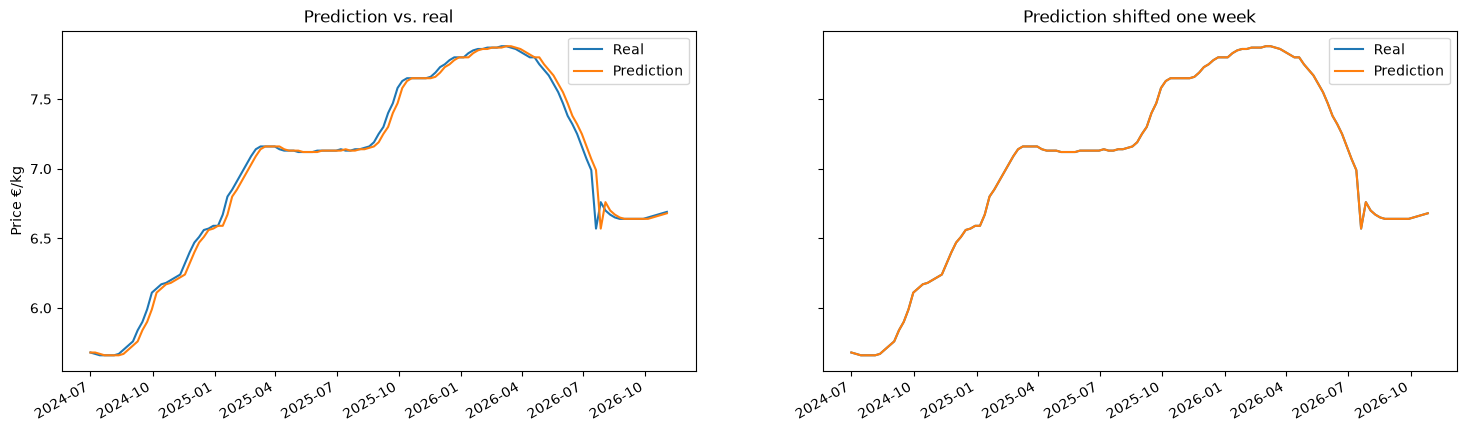

In [15]:
report('Persistencia', last_price)

**Modelo 1: LSTM univariante (precios).**

In [16]:
def build_lstm(input_shape: tuple[int, ...], output_dim: int) -> tf.keras.Model:
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Capa LSTM
    lstm0 = tf.keras.layers.LSTM(32, activation='tanh', recurrent_activation='relu')(inputs)
    # Capa densa
    dense0 = tf.keras.layers.Dense(8, activation='relu')(lstm0)
    # Capa de salida
    output = tf.keras.layers.Dense(output_dim, activation='linear')(dense0)

    model = tf.keras.models.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=LEARNING_RATE), loss='mse')
    return model

Tiempo de entrenamiento: 7.97 s


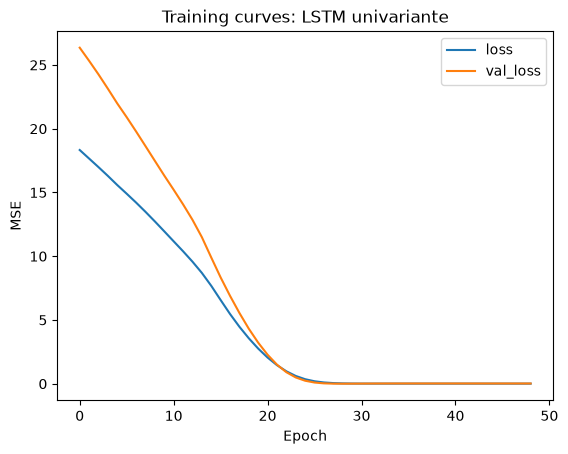

Train                      Val                      Test  \
                     MAE   RMSE Max error     MAE    RMSE Max error     MAE   
LSTM univariante  0.1162  0.131    0.8206  0.0333  0.0388    0.0884  0.0485   

                                    
                    RMSE Max error  
LSTM univariante  0.0698    0.4627

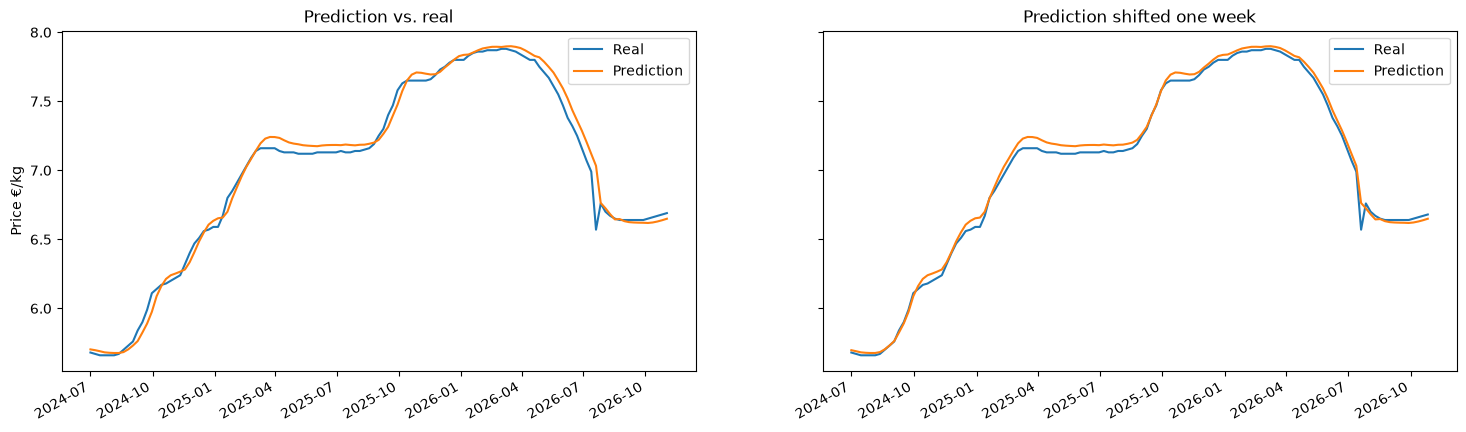

In [17]:
x_uni = x[:, :, [target_idx]]

set_seed()
model = build_lstm(x_uni.shape[1:], y.shape[1])
run('LSTM univariante', model, x_uni, y)

**Modelo 2: LSTM multivariante (precios).**

Tiempo de entrenamiento: 8.65 s


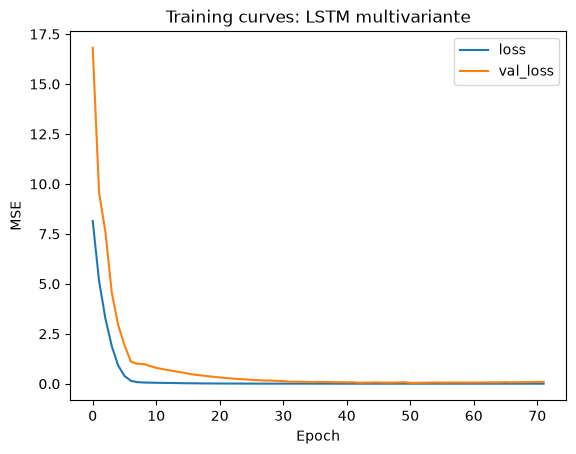

Train                       Val                    \
                       MAE    RMSE Max error     MAE    RMSE Max error   
LSTM multivariante  0.0304  0.0562     0.691  0.0406  0.0624    0.3387   

                      Test                    
                       MAE    RMSE Max error  
LSTM multivariante  0.0733  0.1056     0.462

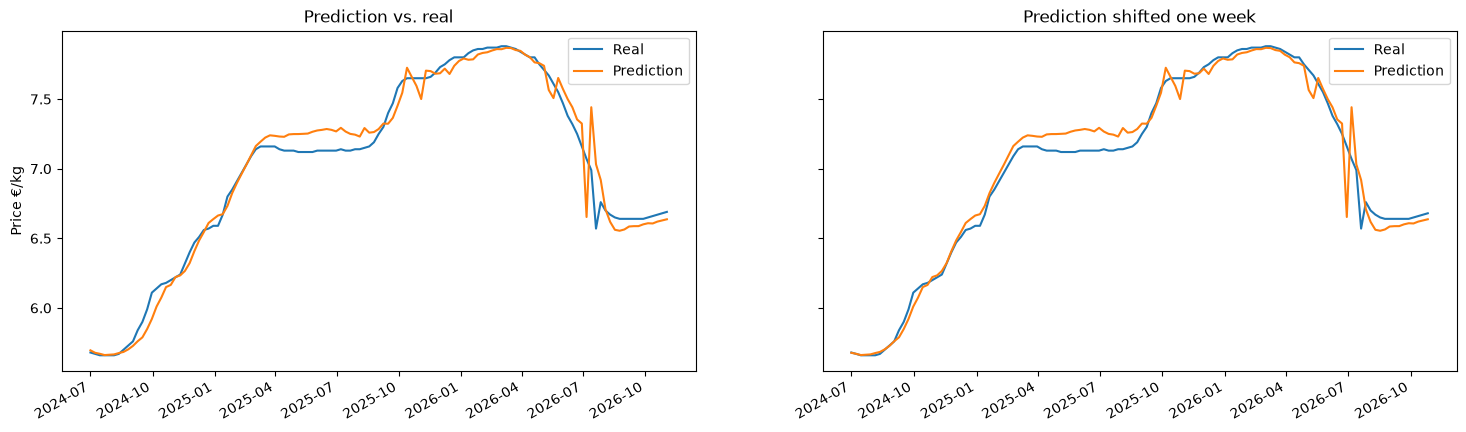

In [18]:
set_seed()
model = build_lstm(x.shape[1:], y.shape[1])
run('LSTM multivariante', model, x, y)

**Modelo 3: LSTM univariante (log-retornos).**

Tiempo de entrenamiento: 100.41 s


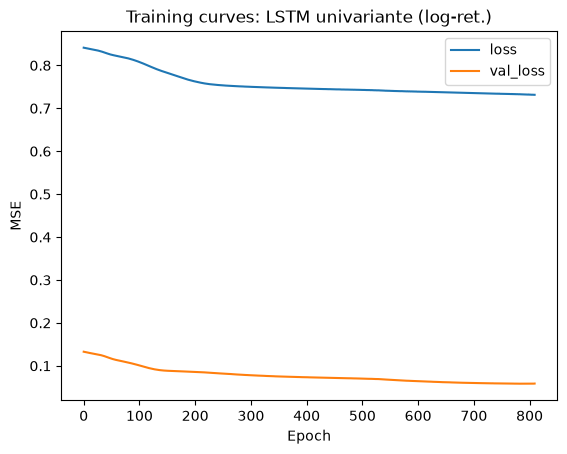

Train                       Val          \
                                MAE    RMSE Max error     MAE    RMSE   
LSTM univariante (log-ret.)  0.0113  0.0427     0.794  0.0099  0.0132   

                                         Test                    
                            Max error     MAE    RMSE Max error  
LSTM univariante (log-ret.)    0.0376  0.0283  0.0635    0.3814

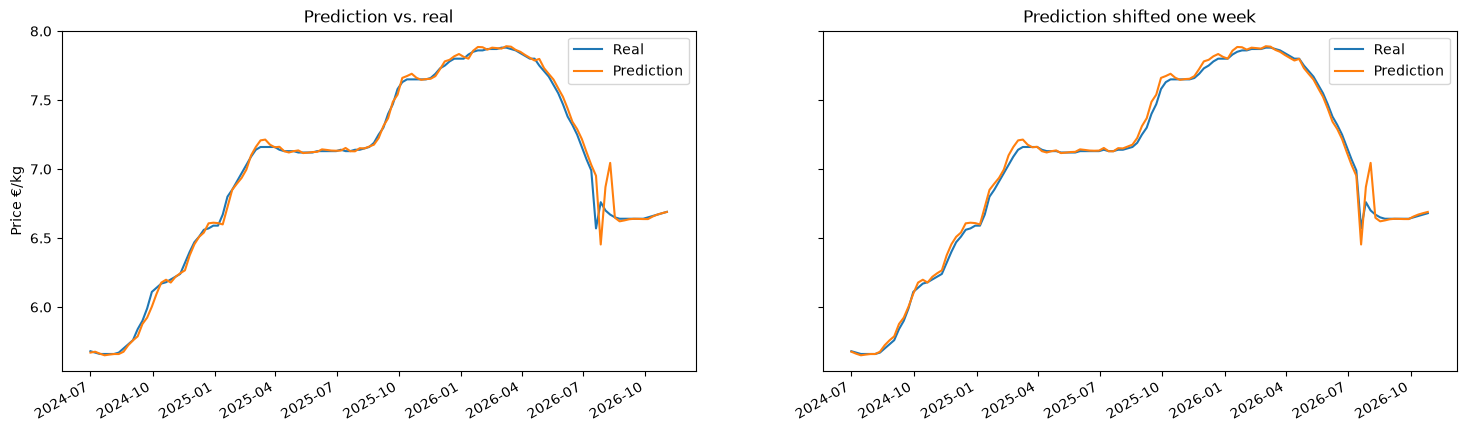

In [19]:
x_log_uni = x_log[:, :, [target_idx]]

set_seed()
model = build_lstm(x_log_uni.shape[1:], y_log.shape[1])
run('LSTM univariante (log-ret.)', model, x_log_uni, y_log, last_price)

**Modelo 4: LSTM multivariante (log-retornos).**

Tiempo de entrenamiento: 16.97 s


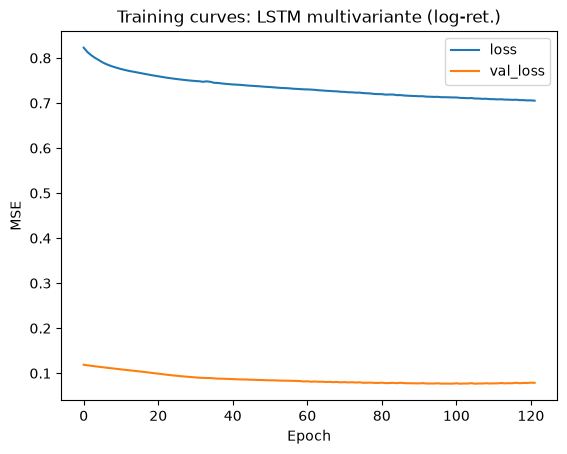

Train                       Val          \
                                  MAE    RMSE Max error     MAE    RMSE   
LSTM multivariante (log-ret.)  0.0102  0.0422    0.7967  0.0111  0.0144   

                                           Test                    
                              Max error     MAE    RMSE Max error  
LSTM multivariante (log-ret.)    0.0347  0.0248  0.0516    0.3452

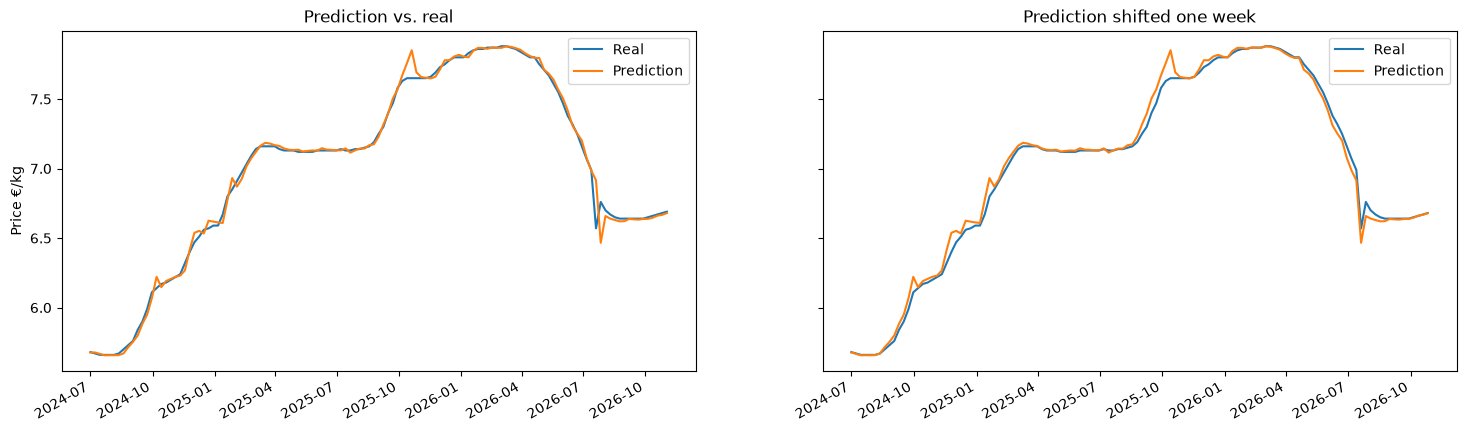

In [20]:
set_seed()
model = build_lstm(x_log.shape[1:], y_log.shape[1])
run('LSTM multivariante (log-ret.)', model, x_log, y_log, last_price)

## Resumen

In [21]:
summary(results)

Train                       Val          \
                                  MAE    RMSE Max error     MAE    RMSE   
Persistencia                   0.0113  0.0458    0.8000  0.0132  0.0199   
LSTM univariante               0.1162  0.1310    0.8206  0.0333  0.0388   
LSTM multivariante             0.0304  0.0562    0.6910  0.0406  0.0624   
LSTM univariante (log-ret.)    0.0113  0.0427    0.7940  0.0099  0.0132   
LSTM multivariante (log-ret.)  0.0102  0.0422    0.7967  0.0111  0.0144   

                                           Test                    
                              Max error     MAE    RMSE Max error  
Persistencia                     0.0500  0.0326  0.0588    0.4200  
LSTM univariante                 0.0884  0.0485  0.0698    0.4627  
LSTM multivariante               0.3387  0.0733  0.1056    0.4620  
LSTM univariante (log-ret.)      0.0376  0.0283  0.0635    0.3814  
LSTM multivariante (log-ret.)    0.0347  0.0248  0.0516    0.3452